# Курсовая работа

# Предсказание наличия гепатита С по данным лабораторных и демографических показателей пациентов с применением методов машинного обучения.

Датасет - https://www.kaggle.com/datasets/fedesoriano/hepatitis-c-dataset/. Набор данных содержит лабораторные показатели доноров крови и пациентов с гепатитом С, а также демографические показатели, такие как возраст. Данные были получены из хранилища машинного обучения UCI

Все атрибуты, кроме Категории и Пола, являются числовыми.
Атрибуты с 1 по 4 относятся к данным пациента:
1) X (Patient ID/No.)
2) Category (diagnosis) (values: '0=Blood Donor', '0s=suspect Blood Donor', '1=Hepatitis', '2=Fibrosis', '3=Cirrhosis')
3) Age (in years)
4) Sex (f,m)

Атрибуты с 5 по 14 относятся к лабораторным данным:

5) ALB - Albumin Blood Test
6) ALP - Alkaline phosphatase
7) ALT - Alanine Transaminase
8) AST - Aspartate Transaminase
9) BIL - Bilirubin
10) CHE - Acetylcholinesterase
11) CHOL - Cholesterol
12) CREA - Creatinine
13) GGT - Gamma-Glutamyl Transferase
14) PROT - Proteins

Целевой атрибут для классификации - Category (2): Доноры крови против Пациентов с Гепатитом С (включая его прогрессирование («только» гепатит С, фиброз, цирроз)).

## Импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_curve, roc_auc_score
from sklearn.preprocessing import RobustScaler

import os
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import classification_report

import shap
from sklearn.inspection import permutation_importance


## Импорт набора данных


In [ ]:
import kagglehub

path = kagglehub.dataset_download("fedesoriano/hepatitis-c-dataset")

print("Path to dataset files:", path)
print("Files in directory:", os.listdir(path))

100%|██████████| 14.8k/14.8k [00:00<00:00, 9.44MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/fedesoriano/hepatitis-c-dataset/versions/1
Files in directory: ['HepatitisCdata.csv']


In [ ]:
df = pd.read_csv(os.path.join(path, 'HepatitisCdata.csv'))

## Информация о данных

In [ ]:
df

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610,611,3=Cirrhosis,62,f,32.0,416.6,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5
611,612,3=Cirrhosis,64,f,24.0,102.8,2.9,44.4,20.0,1.54,3.02,63.0,35.9,71.3
612,613,3=Cirrhosis,64,f,29.0,87.3,3.5,99.0,48.0,1.66,3.63,66.7,64.2,82.0
613,614,3=Cirrhosis,46,f,33.0,NaN,39.0,62.0,20.0,3.56,4.20,52.0,50.0,71.0


In [ ]:
df = df.drop("Unnamed: 0", axis=1)

In [ ]:
df.shape

(615, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Category  615 non-null    object 
 1   Age       615 non-null    int64  
 2   Sex       615 non-null    object 
 3   ALB       614 non-null    float64
 4   ALP       597 non-null    float64
 5   ALT       614 non-null    float64
 6   AST       615 non-null    float64
 7   BIL       615 non-null    float64
 8   CHE       615 non-null    float64
 9   CHOL      605 non-null    float64
 10  CREA      615 non-null    float64
 11  GGT       615 non-null    float64
 12  PROT      614 non-null    float64
dtypes: float64(10), int64(1), object(2)
memory usage: 62.6+ KB


In [ ]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Age,615.0,47.408,10.055,19.00,39.000,47.00,54.000,77.00
ALB,614.0,41.620,5.781,14.90,38.800,41.95,45.200,82.20
ALP,597.0,68.284,26.028,11.30,52.500,66.20,80.100,416.60
ALT,614.0,28.451,25.470,0.90,16.400,23.00,33.075,325.30
AST,615.0,34.786,33.091,10.60,21.600,25.90,32.900,324.00
BIL,615.0,11.397,19.673,0.80,5.300,7.30,11.200,254.00
CHE,615.0,8.197,2.206,1.42,6.935,8.26,9.590,16.41
CHOL,605.0,5.368,1.133,1.43,4.610,5.30,6.060,9.67
CREA,615.0,81.288,49.756,8.00,67.000,77.00,88.000,1079.10
GGT,615.0,39.533,54.661,4.50,15.700,23.30,40.200,650.90


## Пропущенные значения, дубликаты

In [ ]:
pd.DataFrame({
    'Количество': df.isnull().sum(),
    'Процент %': (df.isnull().sum() / len(df) * 100).round(2)
})


,Количество,Процент %
Category,0,0.00
Age,0,0.00
Sex,0,0.00
ALB,1,0.16
ALP,18,2.93
ALT,1,0.16
AST,0,0.00
BIL,0,0.00
CHE,0,0.00
CHOL,10,1.63


In [ ]:
df.duplicated().sum()

np.int64(0)

## Визуализация

Настройки

In [ ]:
sns.set_theme(style="darkgrid", palette='Set2')
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.figsize'] = (7, 7)
plt.rcParams['font.size'] = 12

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols

['Age',
 'ALB',
 'ALP',
 'ALT',
 'AST',
 'BIL',
 'CHE',
 'CHOL',
 'CREA',
 'GGT',
 'PROT']

Корреляционная матрица признаков


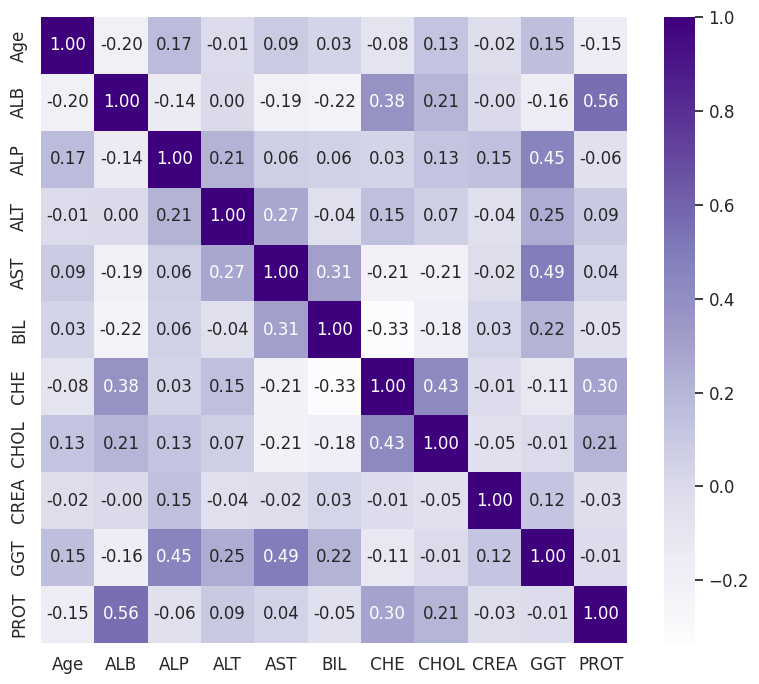

In [ ]:
plt.figure(figsize=(8, 7))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='Purples',
            fmt=".2f")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Распределение в целевой переменной

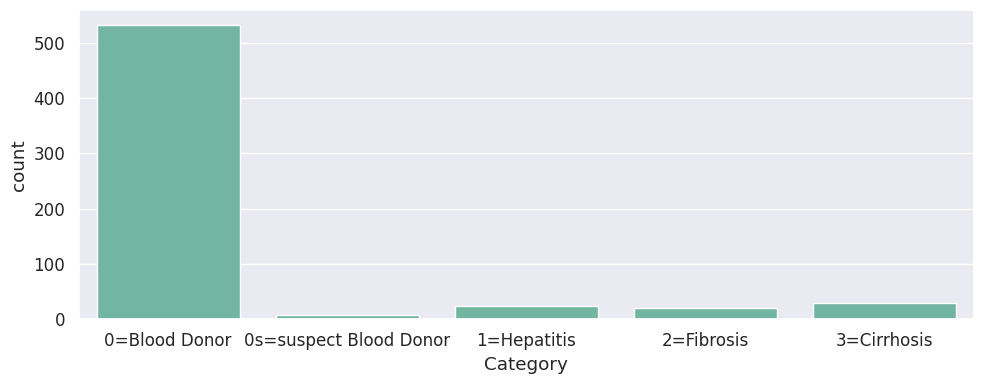

,count
Category,
0=Blood Donor,533
3=Cirrhosis,30
1=Hepatitis,24
2=Fibrosis,21
0s=suspect Blood Donor,7


In [ ]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='Category')

plt.tight_layout()
plt.show()

df['Category'].value_counts()

Распределение по полу

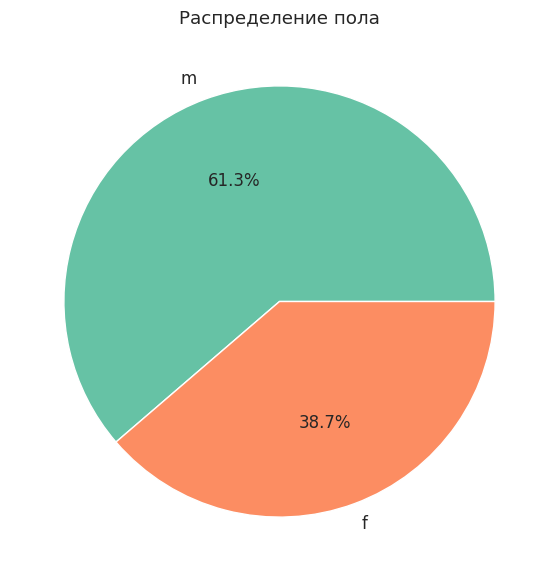

In [ ]:
plt.pie(df["Sex"].value_counts(),
        labels=df["Sex"].value_counts().index,
        autopct='%1.1f%%',
)

plt.title('Распределение пола')
plt.show()

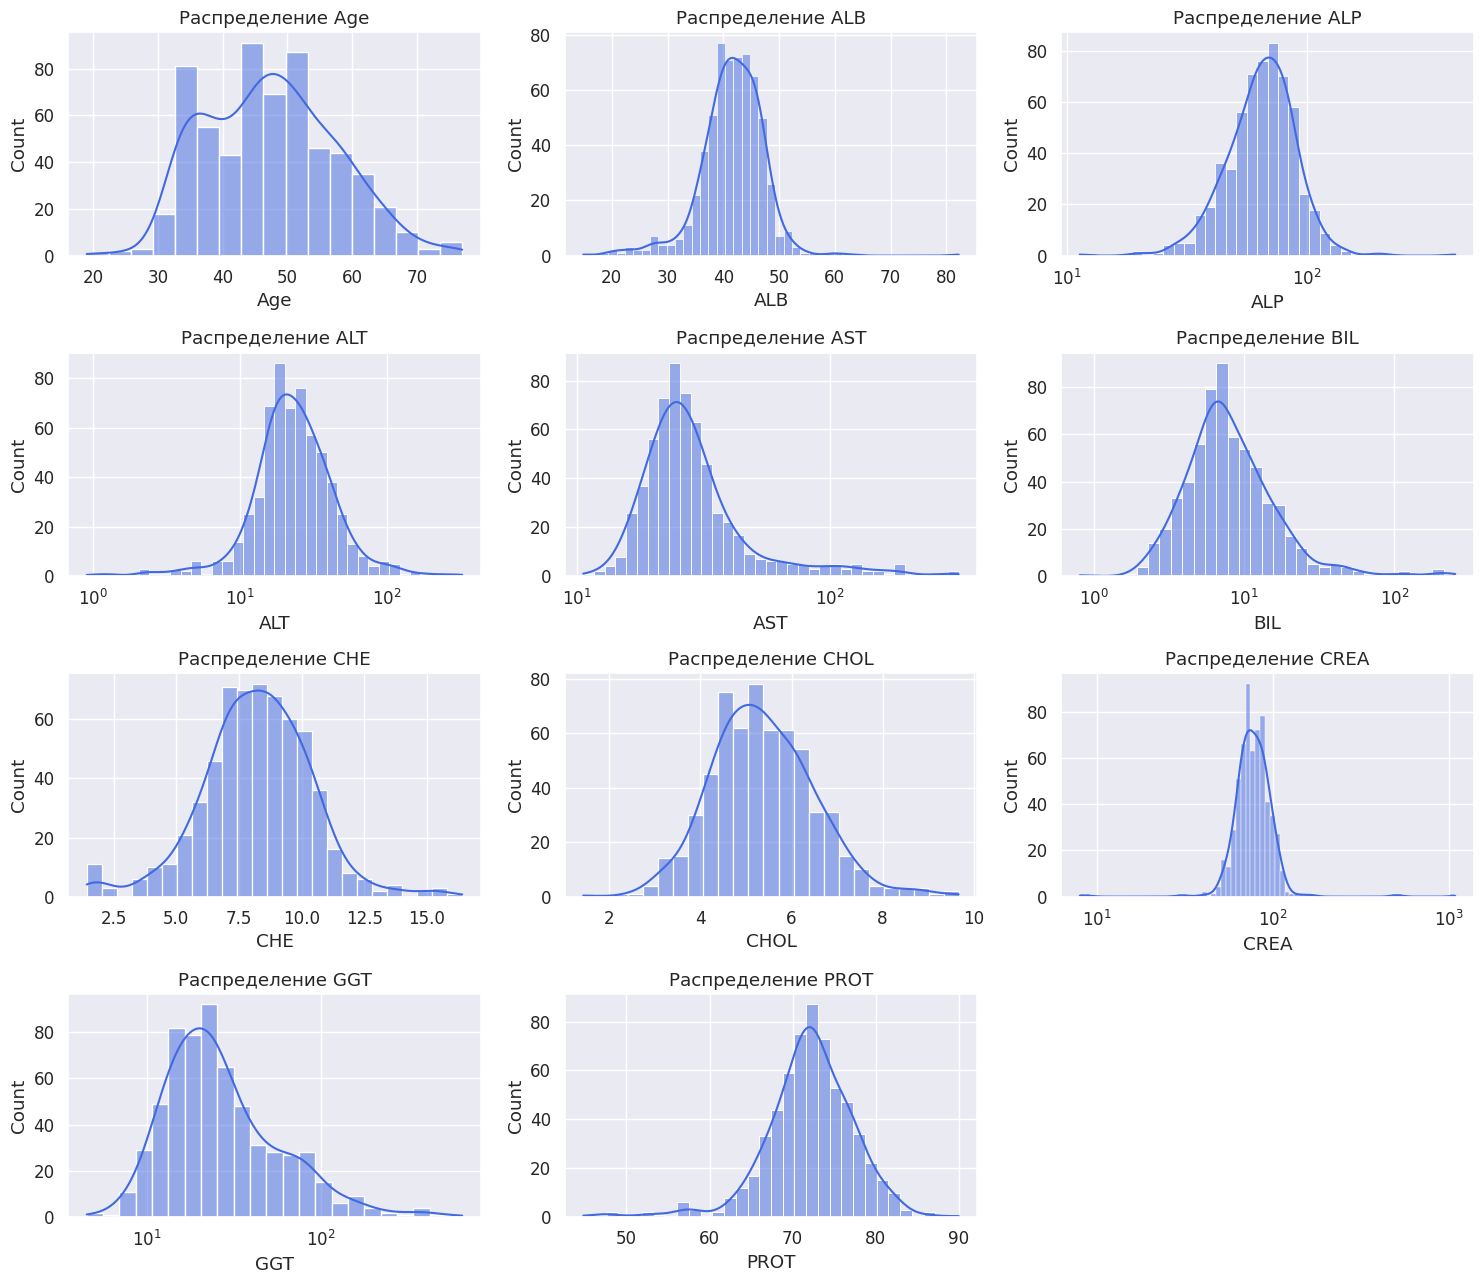

In [ ]:
temp = ["ALP","ALT","AST","BIL","CREA","GGT"]
plt.figure(figsize=(15, 13))
for i, col in enumerate(num_cols):
    plt.subplot(4, 3, i + 1)
    if col in temp:
        sns.histplot(df[col], kde=True, color='royalblue', log_scale=True)
        plt.title(f'Распределение {col}')
    else:
      sns.histplot(df[col], kde=True, color='royalblue')
      plt.title(f'Распределение {col}')
plt.tight_layout()
plt.show()

Гистограммы распределений признаков

Boxplot'ы признаков по категориям диагнозов

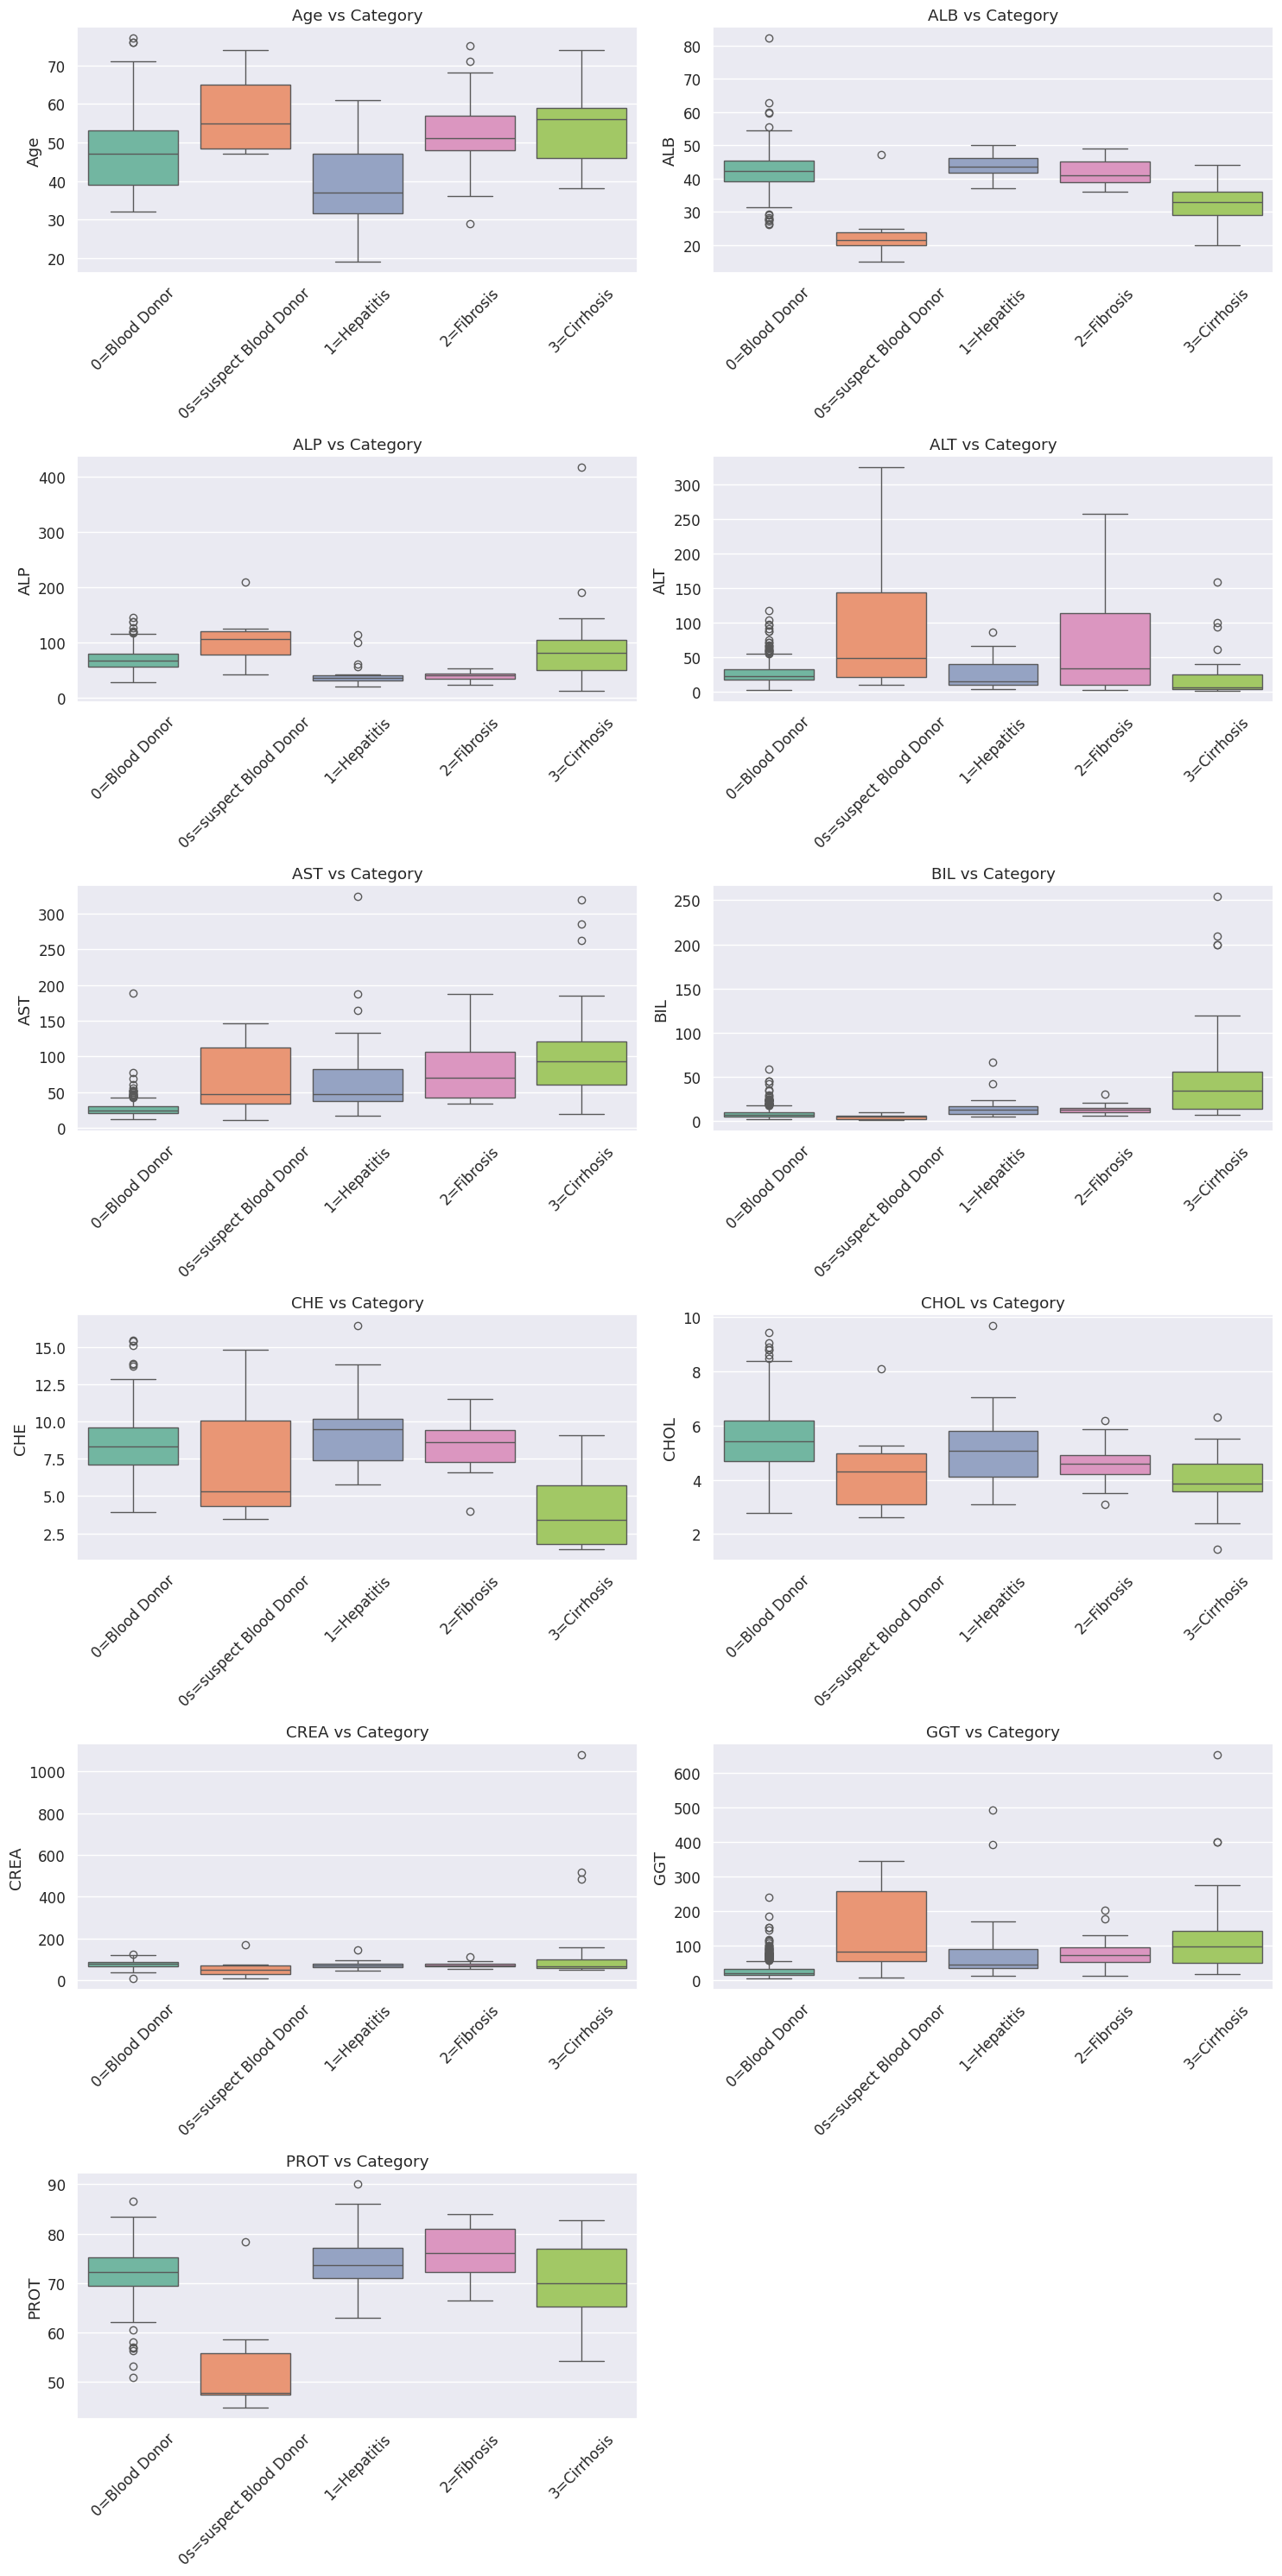

In [ ]:
fig, axes = plt.subplots(6, 2, figsize=(15, 30))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Category', y=col, palette='Set2', ax=axes[i])
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)
    axes[i].set_title(f'{col} vs Category')
    axes[i].set_xlabel('')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

Распределение диагнозов по полу

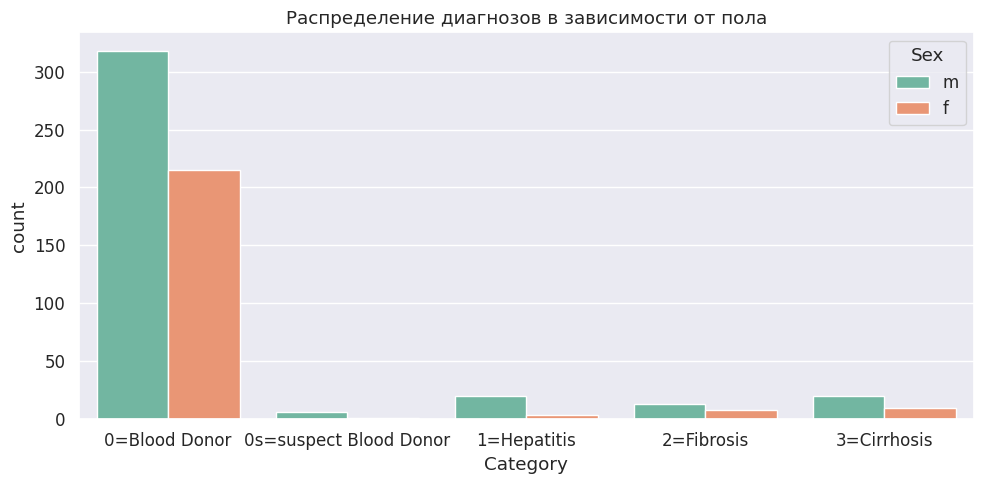

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Category', hue='Sex')
plt.title('Распределение диагнозов в зависимости от пола')
plt.tight_layout()
plt.show()

Взаимосвязь ферментов (AST vs ALT) с учетом пола

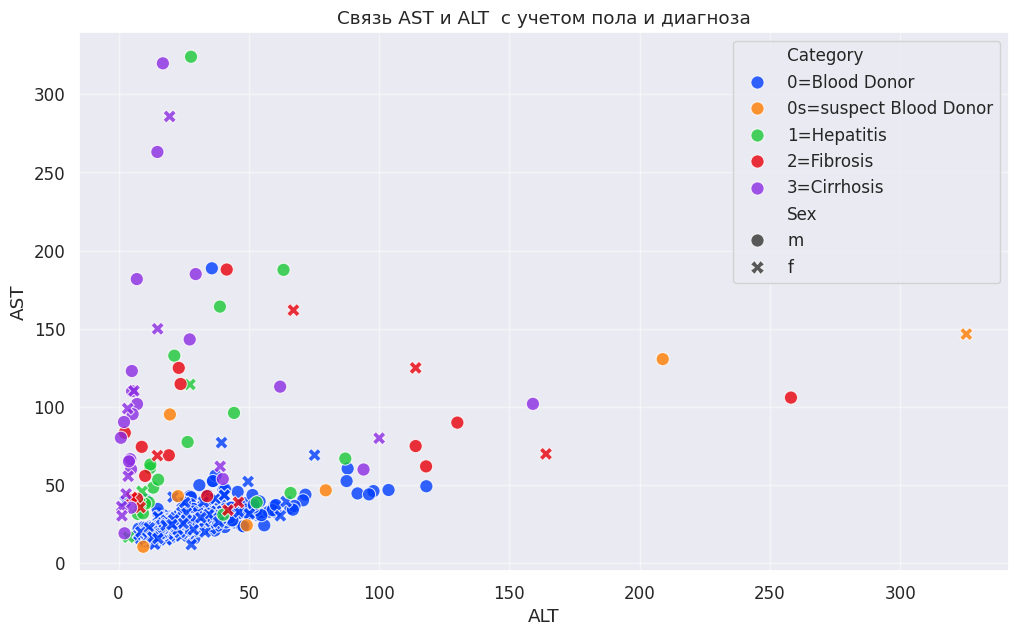

In [ ]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='ALT',y='AST', hue='Category',
                style='Sex',    # точки разной формы для мужчин и женщин
                alpha=0.8,
                s=90,           # размер точек
                palette='bright')


plt.title('Связь AST и ALT  с учетом пола и диагноза')
plt.grid(True, ls="-", alpha=0.5)
plt.show()

Pairplot лабораторных показателей

<Figure size 1000x500 with 0 Axes>

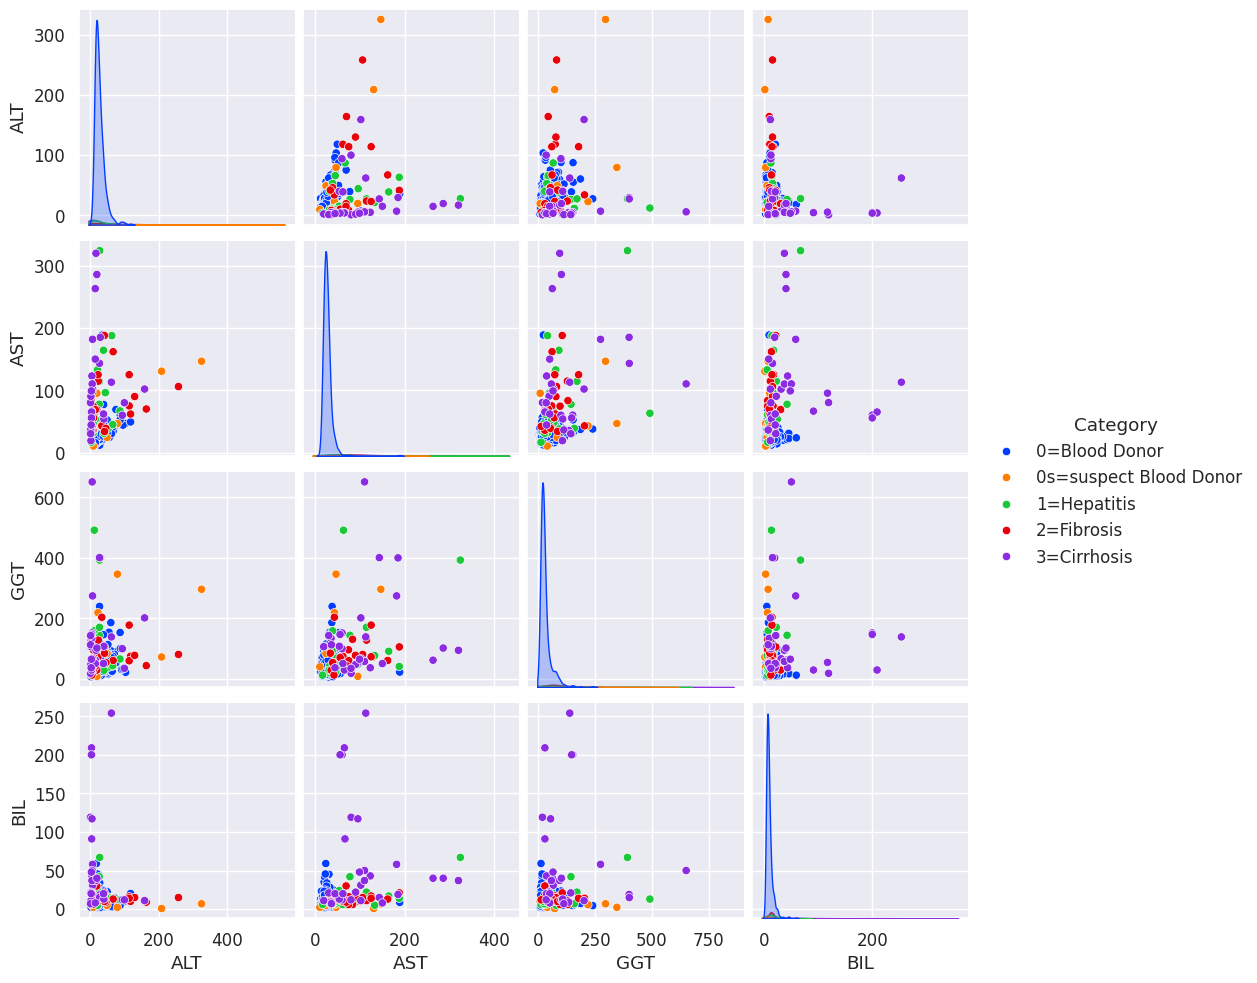

In [ ]:
plt.figure(figsize=(10,5))
sns.pairplot(df, hue='Category', vars=['ALT', 'AST', 'GGT', 'BIL'], palette='bright', diag_kws={'clip': (-5, None)})
# plt.suptitle('Взаимосвязь показателей лабораторной диагностики', y=1.01)
plt.show()


## Кодирование категориальных признаков

In [ ]:
df_clean = df.copy()

df_clean['Sex'] = df_clean['Sex'].map({'m': 0, 'f': 1})

df_clean['Category'] = df_clean['Category'].replace({
    '0=Blood Donor': 0,
    '0s=suspect Blood Donor': 0,
    '1=Hepatitis': 1,
    '2=Fibrosis': 1,
    '3=Cirrhosis': 1
})

In [ ]:
X = df_clean.drop('Category', axis=1)
y = df_clean['Category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
cols_with_nan = ['ALB', 'ALP', 'ALT', 'CHOL', 'PROT']

for col in cols_with_nan:
    train_median = X_train[col].median()

    X_train[col] = X_train[col].fillna(train_median)
    X_test[col] = X_test[col].fillna(train_median)

In [ ]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

def handle_outliers_train_test(train_data, test_data, columns):
    for col in columns:
        lower = train_data[col].quantile(0.01)
        upper = train_data[col].quantile(0.99)

        train_data[col] = train_data[col].clip(lower, upper)
        test_data[col] = test_data[col].clip(lower, upper)
    return train_data, test_data

X_train, X_test = handle_outliers_train_test(X_train, X_test, num_cols)

In [ ]:
robust_scaler = RobustScaler()

X_train_scaled = robust_scaler.fit_transform(X_train)
X_test_scaled = robust_scaler.transform(X_test)

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

## Модели

In [ ]:
from sklearn.svm import SVC


In [ ]:
param_SVC = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],        # регуляризация (чем меньше C, тем сильнее регуляризация)
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'], # тип ядра
    'degree': [2, 3, 4],                           # для полиномиального ядра (kernel='poly')
    'gamma': ['scale', 'auto', 0.1, 1, 10],       # радиус влияния для rbf/poly/sigmoid
    'class_weight': [None, 'balanced']            # балансировка классов
}

grid_svc = GridSearchCV(SVC(random_state=42), param_SVC, cv=5, scoring='f1', n_jobs=-1)
grid_svc.fit(X_train_scaled, y_train)


GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'class_weight': [None, 'balanced'],
                         'degree': [2, 3, 4],
                         'gamma': ['scale', 'auto', 0.1, 1, 10],
                         'kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
             scoring='f1')

In [ ]:
print(f"Лучшие параметры: {grid_svc.best_params_}")

y_train_pred_lr = grid_svc.predict(X_train_scaled)
y_test_pred_lr = grid_svc.predict(X_test_scaled)

print("\n SVC метрики на обучающей выборке ")
print(classification_report(y_train, y_train_pred_lr))

print("\n SVC метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_lr))

Лучшие параметры: {'C': 10, 'class_weight': None, 'degree': 2, 'gamma': 'auto', 'kernel': 'poly'}

 SVC метрики на обучающей выборке 
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       378
           1       1.00      0.96      0.98        52

    accuracy                           1.00       430
   macro avg       1.00      0.98      0.99       430
weighted avg       1.00      1.00      1.00       430


 SVC метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       162
           1       0.90      0.83      0.86        23

    accuracy                           0.97       185
   macro avg       0.94      0.91      0.92       185
weighted avg       0.97      0.97      0.97       185



---

In [ ]:
param_rf = {
    'n_estimators': [15, 50, 100, 200],
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 3, 4],
    'max_leaf_nodes': [None, 10, 20],
    'class_weight': ['balanced', None]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_rf,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_rf.fit(X_train_scaled, y_train)

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'class_weight': ['balanced', None],
                         'max_depth': [3, 5, 7, 10],
                         'max_leaf_nodes': [None, 10, 20],
                         'min_samples_leaf': [2, 3, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [15, 50, 100, 200]},
             scoring='f1', verbose=1)

In [ ]:
print(f"Лучшие параметры: {grid_rf.best_params_}")

y_train_pred_rf = grid_rf.predict(X_train_scaled)
y_test_pred_rf = grid_rf.predict(X_test_scaled)

print("\n Random Forest метрики на обучающей выборке ")
print(classification_report(y_train, y_train_pred_rf))

print("\n Random Forest метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_rf))

Лучшие параметры: {'class_weight': 'balanced', 'max_depth': 7, 'max_leaf_nodes': None, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200}

 Random Forest метрики на обучающей выборке 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       378
           1       0.98      0.98      0.98        52

    accuracy                           1.00       430
   macro avg       0.99      0.99      0.99       430
weighted avg       1.00      1.00      1.00       430


 Random Forest метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       162
           1       1.00      0.83      0.90        23

    accuracy                           0.98       185
   macro avg       0.99      0.91      0.95       185
weighted avg       0.98      0.98      0.98       185



---

In [ ]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos

print(f"Класс 0 (доноры): {neg}")
print(f"Класс 1 (пациенты): {pos}")
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

Класс 0 (доноры): 378
Класс 1 (пациенты): 52
scale_pos_weight = 7.27


In [ ]:
param_xgb = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'eval_metric': ['logloss', 'auc'],
    'scale_pos_weight': [scale_pos_weight, 1],
    'reg_alpha': [0, 0.01, 0.1],      # L1 регуляризация (lasso) обнуляет неважные признаки
    'reg_lambda': [0.1, 0.5, 1.0],    # L2 регуляризация (ridge) уменьшает веса признаков
    'gamma': [0, 0.01, 0.1]           # минимальное улучшение для создания нового листа (pruning)
}

grid_xgb = GridSearchCV(XGBClassifier(), param_xgb, cv=5, scoring='f1', n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=Non...
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'eval_metric': ['logloss', 'auc'],
                         'gamma': [0, 0.01, 0.1],
                         'learning_rate': [0.01, 0.05, 0.1],
                         'max_depth': [3, 5, 7],
                         'n_estimators': [100, 150, 200],
                         'reg_alpha': [0, 0.01, 0.1],
                         'reg_lambda': [0.1, 0.5, 1.0],
                         'scale_pos_weight': [np.float64(7.269230769230769),
                                              1]},
             scoring='f1')

In [ ]:
print(f"Лучшие параметры: {grid_xgb.best_params_}")

y_train_pred_xgb = grid_xgb.predict(X_train_scaled)
y_test_pred_xgb = grid_xgb.predict(X_test_scaled)

print("\n XGboost метрики на обучающей выборке ")
print(classification_report(y_train, y_train_pred_xgb))

print("\n XGboost метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_xgb))

Лучшие параметры: {'eval_metric': 'logloss', 'gamma': 0.1, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 0.1, 'scale_pos_weight': 1}

 XGboost метрики на обучающей выборке 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       378
           1       1.00      1.00      1.00        52

    accuracy                           1.00       430
   macro avg       1.00      1.00      1.00       430
weighted avg       1.00      1.00      1.00       430


 XGboost метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       162
           1       1.00      0.91      0.95        23

    accuracy                           0.99       185
   macro avg       0.99      0.96      0.97       185
weighted avg       0.99      0.99      0.99       185



# Best models

In [ ]:
best_svc = SVC(
    C=10,
    class_weight=None,
    degree=2,
    gamma='auto',
    kernel='poly',
    random_state=42
)
best_svc.fit(X_train_scaled, y_train)

y_train_pred_svc = best_svc.predict(X_train_scaled)
y_test_pred_svc = best_svc.predict(X_test_scaled)

print("SVC метрики на обучающей выборке")
print(classification_report(y_train, y_train_pred_svc))

print("SVC метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_svc))

SVC метрики на обучающей выборке
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       378
           1       1.00      0.96      0.98        52

    accuracy                           1.00       430
   macro avg       1.00      0.98      0.99       430
weighted avg       1.00      1.00      1.00       430

SVC метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       162
           1       0.90      0.83      0.86        23

    accuracy                           0.97       185
   macro avg       0.94      0.91      0.92       185
weighted avg       0.97      0.97      0.97       185



In [ ]:
best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_split=2,
    min_samples_leaf=3,
    max_leaf_nodes=None,
    class_weight='balanced',
    random_state=42
)
best_rf.fit(X_train_scaled, y_train)

y_train_pred_rf = best_rf.predict(X_train_scaled)
y_test_pred_rf = best_rf.predict(X_test_scaled)

print("Random Forest метрики на обучающей выборке")
print(classification_report(y_train, y_train_pred_rf))

print("Random Forest метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_rf))


Random Forest метрики на обучающей выборке
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       378
           1       0.98      0.98      0.98        52

    accuracy                           1.00       430
   macro avg       0.99      0.99      0.99       430
weighted avg       1.00      1.00      1.00       430

Random Forest метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       162
           1       1.00      0.83      0.90        23

    accuracy                           0.98       185
   macro avg       0.99      0.91      0.95       185
weighted avg       0.98      0.98      0.98       185



In [ ]:
best_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    eval_metric='logloss',
    reg_alpha=0,
    reg_lambda=0.1,
    gamma=0.1,
    scale_pos_weight=1,
    random_state=42
)
best_xgb.fit(X_train_scaled, y_train)

y_train_pred_xgb = best_xgb.predict(X_train_scaled)
y_test_pred_xgb = best_xgb.predict(X_test_scaled)

print("XGBoost метрики на обучающей выборке")
print(classification_report(y_train, y_train_pred_xgb))

print("XGBoost метрики на тестовой выборке")
print(classification_report(y_test, y_test_pred_xgb))

XGBoost метрики на обучающей выборке
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       378
           1       1.00      1.00      1.00        52

    accuracy                           1.00       430
   macro avg       1.00      1.00      1.00       430
weighted avg       1.00      1.00      1.00       430

XGBoost метрики на тестовой выборке
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       162
           1       1.00      0.91      0.95        23

    accuracy                           0.99       185
   macro avg       0.99      0.96      0.97       185
weighted avg       0.99      0.99      0.99       185



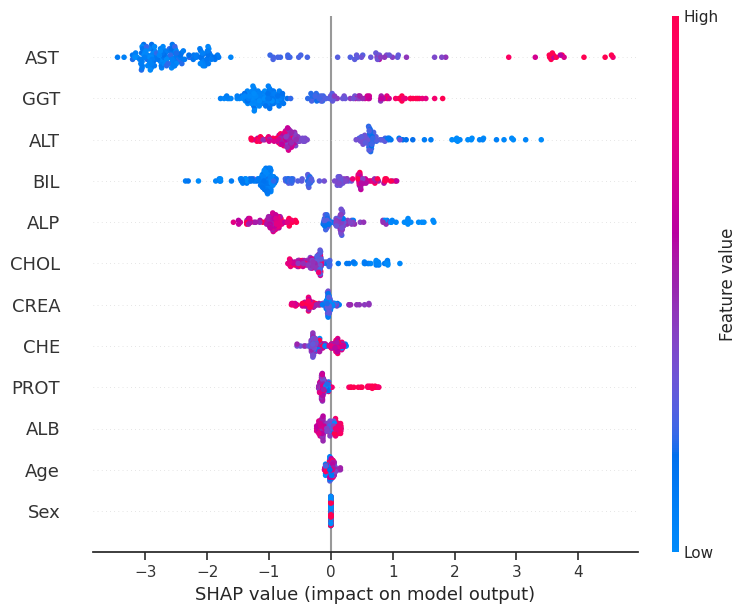

In [ ]:
sns.set_style("white")
explainer_shap = shap.TreeExplainer(best_xgb)
shap_values = explainer_shap(X_test_scaled)
shap.summary_plot(shap_values)


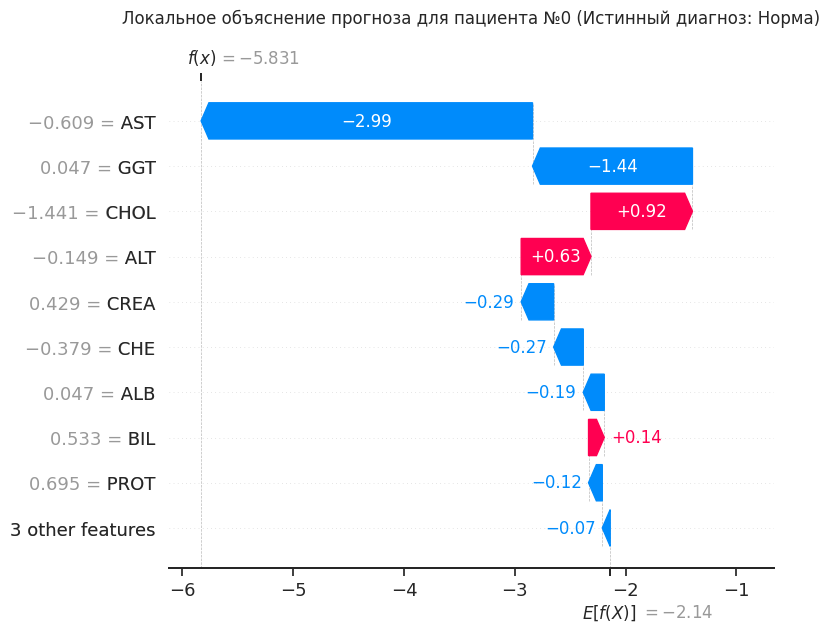

In [ ]:
patient_index0 = 0

true_class = y_test.iloc[patient_index0]
class_label = "Патология" if true_class == 1 else "Норма"

plt.figure(figsize=(10, 5))
plt.title(f"Локальное объяснение прогноза для пациента №{patient_index0} (Истинный диагноз: {class_label})",
          fontsize=12, y=1.1)

shap.plots.waterfall(shap_values[patient_index0], show=False)

plt.tight_layout()
plt.show()

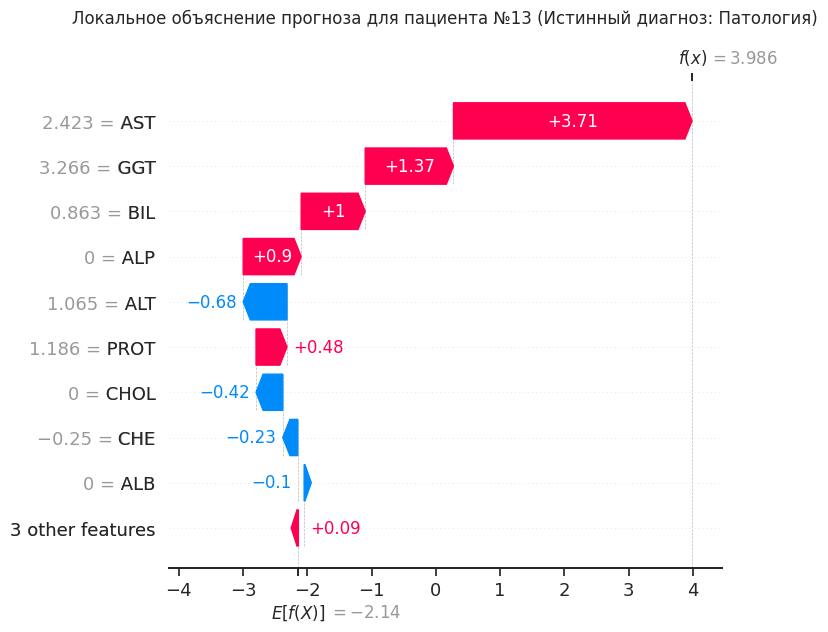

In [ ]:
patient_index1 = 13

true_class = y_test.iloc[patient_index1]
class_label = "Патология" if true_class == 1 else "Норма"

plt.figure(figsize=(10, 5))
plt.title(f"Локальное объяснение прогноза для пациента №{patient_index1} (Истинный диагноз: {class_label})",
          fontsize=12, y=1.1)

shap.plots.waterfall(shap_values[patient_index1], show=False)

plt.tight_layout()
plt.show()

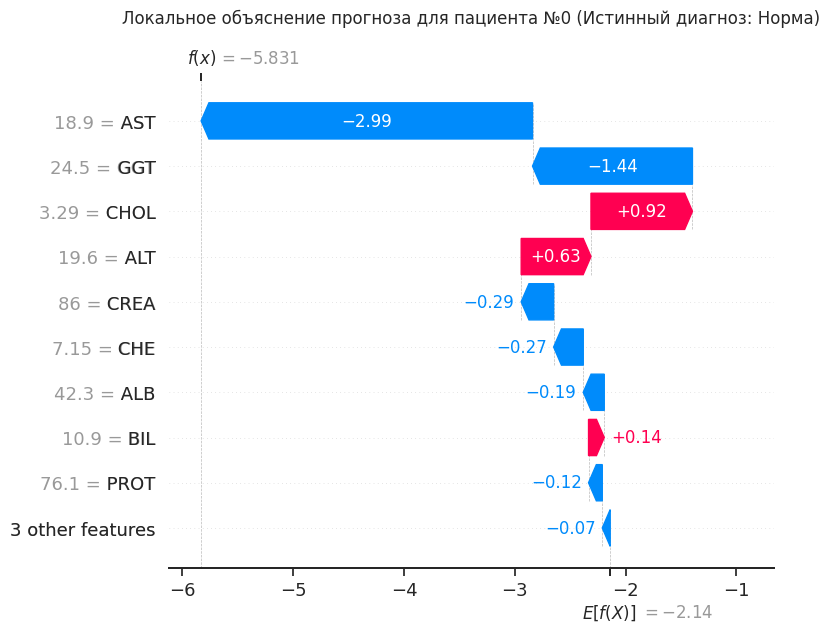

In [ ]:
import copy
import matplotlib.pyplot as plt
import shap

true_class = y_test.iloc[patient_index0]
class_label = "Патология" if true_class == 1 else "Норма"

patient_explanation = copy.deepcopy(shap_values[patient_index0])

patient_explanation.data = X_test.iloc[patient_index0].values

plt.figure(figsize=(10, 5))
plt.title(
    f"Локальное объяснение прогноза для пациента №{patient_index0} (Истинный диагноз: {class_label})",
    fontsize=12,
    y=1.1,
)

shap.plots.waterfall(patient_explanation, show=False)

plt.tight_layout()
plt.show()

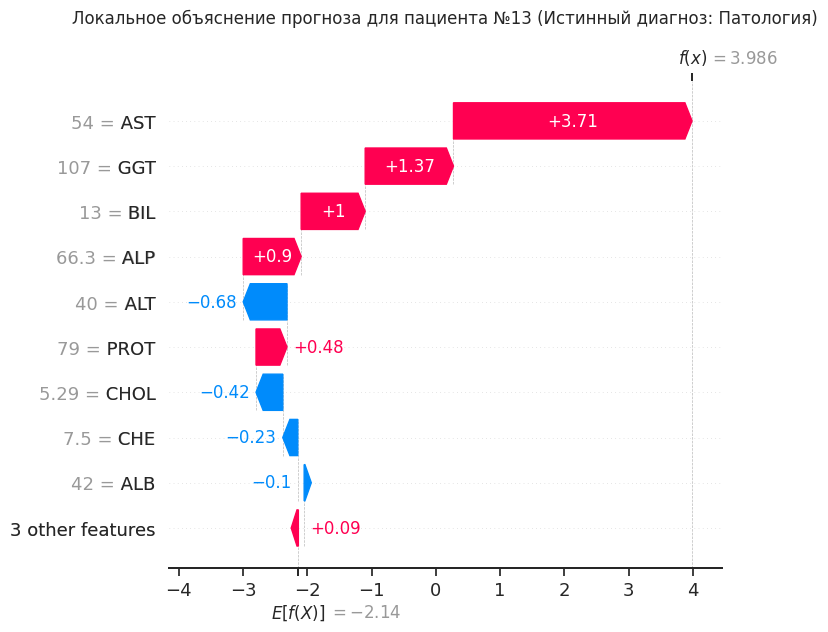

In [ ]:
import copy
import matplotlib.pyplot as plt
import shap


true_class = y_test.iloc[patient_index1]
class_label = "Патология" if true_class == 1 else "Норма"

patient_explanation = copy.deepcopy(shap_values[patient_index1])

patient_explanation.data = X_test.iloc[patient_index1].values

plt.figure(figsize=(10, 5))
plt.title(
    f"Локальное объяснение прогноза для пациента №{patient_index1} (Истинный диагноз: {class_label})",
    fontsize=12,
    y=1.1,
)

shap.plots.waterfall(patient_explanation, show=False)

plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(best_xgb, "xgb_model.joblib")
joblib.dump(robust_scaler, "robust_scaler.joblib")

medians_dict = X_train[num_cols].median().to_dict()
joblib.dump(medians_dict, "medians_dict.joblib")

outlier_bounds = {}
for col in num_cols:
    outlier_bounds[col] = {
        'lower': X_train[col].quantile(0.01),
        'upper': X_train[col].quantile(0.99)
    }
joblib.dump(outlier_bounds, "outlier_bounds.joblib")


['outlier_bounds.joblib']